In [1]:
import pandas as pd

# Reemplaza 'nombre_del_archivo.csv' por el nombre exacto del archivo descargado
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


PART 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. Frequency Tables:

In [17]:
prod_freq_tab = pd.DataFrame(df["title"].value_counts(normalize=True)).round(6)
prod_freq_tab

,proportion
title,
OYhmc Portable Pedal Exerc,0.000296
ScibOr Outdoor Sleeveless Fishing Vest,0.000132
"SHOPPRO Kids Golf Shoes Set, White, with Shoes Bag, UV Sun Protection Arm Sleeves, Golf Pro Cap and Instant Cooling Towel, Outdoor Sneakers, Girls Sport Training, POSMA GSH007WHT39_B (White)",0.000092
Mens Breathable Lace-Up Football Shoes Non-Slip Outdoor Boys Junior Soccer Shoes Training Professional Boots Soccer Sneakers Athletics Training Shoes for Teenager,0.000059
CMP Women's T-shirt,0.000053
...,...
"Motorbike Armour, Motorbike Clothing, Cycling Armour, Youth Chest Protector, Body Chest Spine Protector, Vest Gear For Motocross Skiing Kids Protect Sports Gear For Skateboarding Skating",0.000000
"PROFIRST Waterproof Motorcycle 2 Piece Ladies Motorbike Suit Jacket, Trouser with Minder Boots for women ladies Suit in Corduroy Fabric with CE Approved Armours.",0.000000
Men’s Motorcycle Motorbike Biker Trousers Kevlar Jeans Pants Protective with CE Armour Biker Gear Knee and Hip Armours Protection Clothing for Bikers,0.000000


- Which are the top 5 most listed product categories?

In [18]:
prod_freq_tab.head()

,proportion
title,
OYhmc Portable Pedal Exerc,0.000296
ScibOr Outdoor Sleeveless Fishing Vest,0.000132
"SHOPPRO Kids Golf Shoes Set, White, with Shoes Bag, UV Sun Protection Arm Sleeves, Golf Pro Cap and Instant Cooling Towel, Outdoor Sneakers, Girls Sport Training, POSMA GSH007WHT39_B (White)",0.000092
Mens Breathable Lace-Up Football Shoes Non-Slip Outdoor Boys Junior Soccer Shoes Training Professional Boots Soccer Sneakers Athletics Training Shoes for Teenager,0.000059
CMP Women's T-shirt,0.000053


2. Visualizations:

- Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.

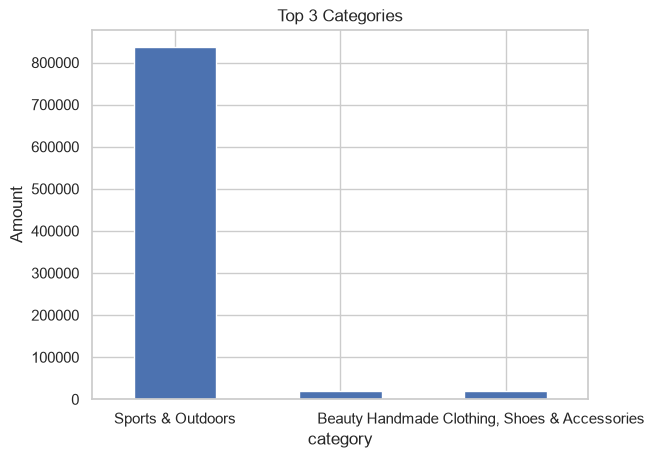

In [27]:
import matplotlib.pyplot as plt

df['category'].value_counts().head(3).plot(kind="bar")

plt.title('Top 3 Categories')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.show()

- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

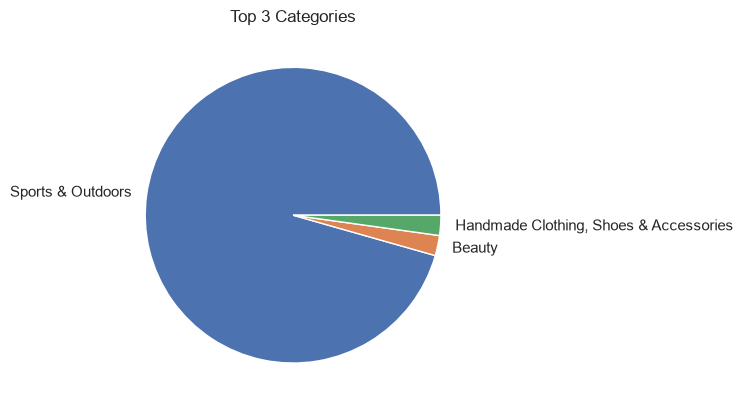

In [31]:
df['category'].value_counts().head(3).plot(kind="pie")

plt.title('Top 3 Categories')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Clearly we can see the "Sports & Outdoors" category is the dominant one whith the biggest amount of products inside.

PART 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. Measures of Centrality:

- Calculate the mean, median, and mode for the price of products.

In [41]:
mean_value = df['price'].mean().round(2)
median_value = df['price'].median()
mode_value = df['price'].mode()
print("Mean:", mean_value)
print("Median:", median_value)
print("Mode:", mode_value)

Mean: 89.24
Median: 19.09
Mode: 0    9.99
Name: price, dtype: float64


- What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [ ]:
# The average price is the highest value, whereas the Median is lower and the mode even lover. this means that the most common price is 9.99, the mode. However, there are some products that are way more expensive so the average price is 89.24.

2. Measures of Dispersion:

- Determine the variance, standard deviation, range, and interquartile range for product price.

In [55]:
price_var = df['price'].var().round(0)
price_std = df['price'].std().round(0)
price_range = df['price'].max() - df['price'].min()

q3 = df['price'].quantile(0.75)
q1 = df['price'].quantile(0.25)
price_iqr = q3 - q1

print(f"Variance: {price_var}")
print(f"Standard Deviation: {price_std}")
print(f"Range: {price_range}")
print(f"IQR: {price_iqr}")

Variance: 119445.0
Standard Deviation: 346.0
Range: 100000.0
IQR: 36.0


- How varied are the product prices? Are there any indicators of a significant spread in prices?

In [ ]:
# The prices are very varied as we can see with the measures of dispersion listed before.

3. Visualizations:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved.

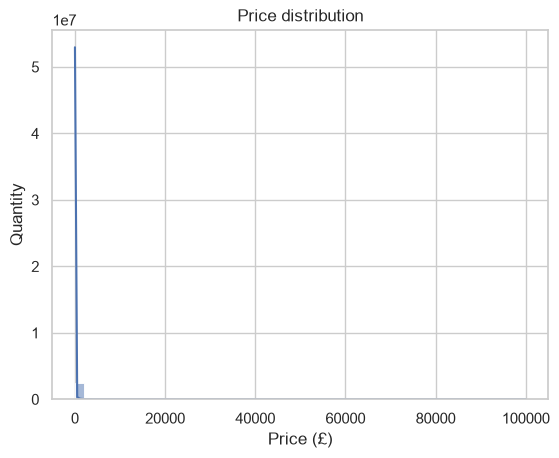

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.set_theme(style="whitegrid")

sns.histplot(df['price'], bins=50, kde=True)

plt.title('Price distribution')
plt.xlabel('Price (£)')
plt.ylabel('Quantity')

plt.show()

In [ ]:
# It is hard to read because the range of prices is very wide but most of them are in a smaller range. To solve this issue, I would take out the outliers of the analysis.

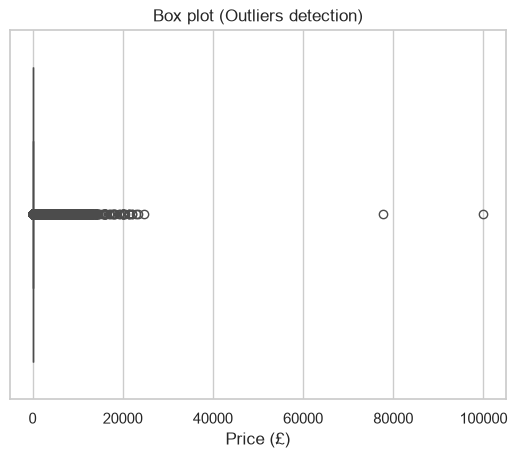

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.set_theme(style="whitegrid")

sns.boxplot(x=df['price'])

plt.title('Box plot (Outliers detection)')
plt.xlabel('Price (£)')

plt.show()

In [ ]:
#There are 2 aoutliers whose price is out of range

PART 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.

In [64]:
mean_value = df['stars'].mean().round(2)
median_value = df['stars'].median()
mode_value = df['stars'].mode()
print("Mean:", mean_value)
print("Median:", median_value)
print("Mode:", mode_value)

Mean: 2.15
Median: 0.0
Mode: 0    0.0
Name: stars, dtype: float64


- How do customers generally rate products? Is there a common trend?

In [ ]:
# The customers normally rate the products with 0 stars. That is the mode value.

2. Measures of Dispersion:

- Determine the variance, standard deviation, and interquartile range for product rating.

In [68]:
stars_var = df['stars'].var().round(0)
stars_std = df['stars'].std().round(0)
stars_range = df['stars'].max() - df['stars'].min()

q3 = df['stars'].quantile(0.75)
q1 = df['stars'].quantile(0.25)
stars_iqr = q3 - q1

print(f"Variance: {stars_var}")
print(f"Standard Deviation: {stars_std}")
print(f"Range: {stars_range}")
print(f"IQR: {stars_iqr}")

Variance: 5.0
Standard Deviation: 2.0
Range: 5.0
IQR: 4.4


- Are the ratings consistent, or is there a wide variation in customer feedback?

In [ ]:
# The ratings seem more consistent compared to the prices, all the values are low and there is not so much variation between the different customers' feedback.

3. Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.

In [69]:
skewness = df['stars'].skew()
kurtosis = df['stars'].kurtosis()

print(f"Skewness: {skewness:.4f}")
print(f"Kurtosis: {kurtosis:.4f}")

Skewness: 0.0812
Kurtosis: -1.9260


- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [ ]:
# It is not normaly distributed as the Kurtosis value is very negative, so it is a very flat bell. They do not lean towards higher or lower values as it is simetric according to the skewness.

4. Visualizations:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

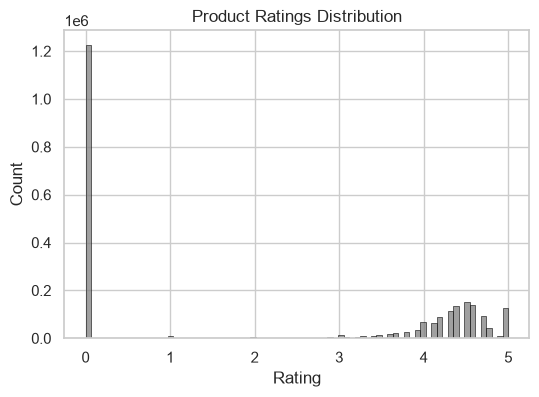

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.histplot(df['stars'], color='gray', edgecolor='black')

plt.title('Product Ratings Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')

plt.show()

In [ ]:
# We can clearly see as we saw with the mode, the most common value is 0.